<a href="https://colab.research.google.com/github/hwoop-dev/DS-3000-Group-Project/blob/Hansen's-branch/DS3000_test_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('/content/paired_streamflow_water_quality.csv')

# Display basic information and the first few rows to verify column names
print(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 335 entries, 0 to 334
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   site               335 non-null    object 
 1   area_type          335 non-null    object 
 2   date               335 non-null    object 
 3   streamflow         335 non-null    float64
 4   water_temperature  335 non-null    float64
dtypes: float64(2), object(3)
memory usage: 13.2+ KB
None


,site,area_type,date,streamflow,water_temperature
0,USGS-01435000,Unknown,2025-01-01,731.0,4.0
1,USGS-01435000,Unknown,2025-01-02,491.0,2.5
2,USGS-01435000,Unknown,2025-01-03,358.0,1.5
3,USGS-01435000,Unknown,2025-01-04,286.0,0.7
4,USGS-01435000,Unknown,2025-01-05,239.0,0.6


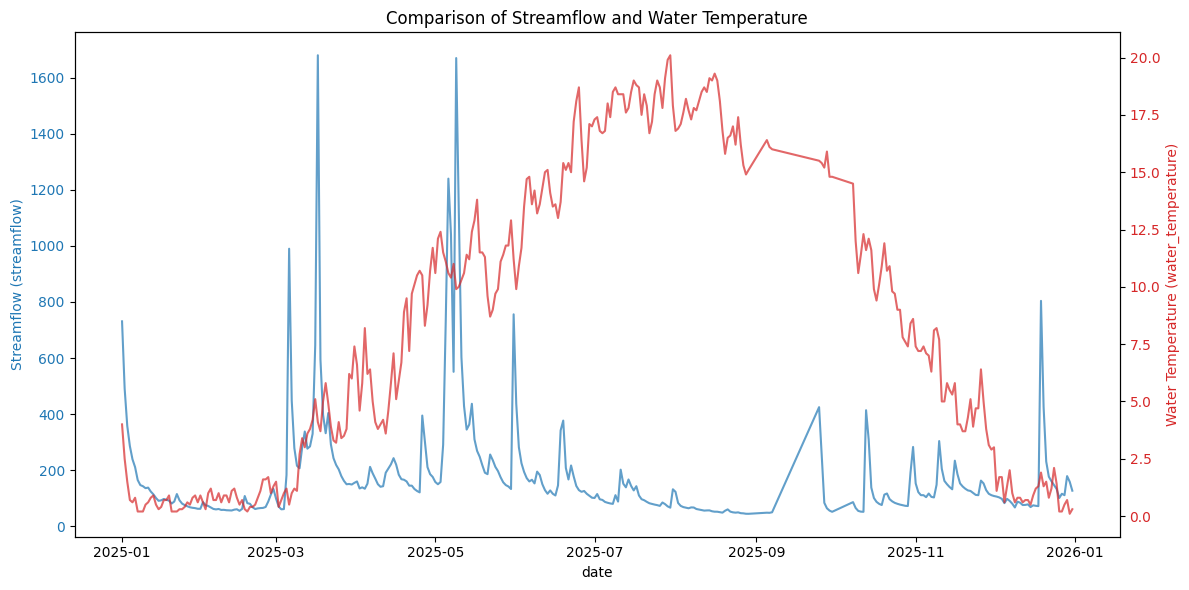

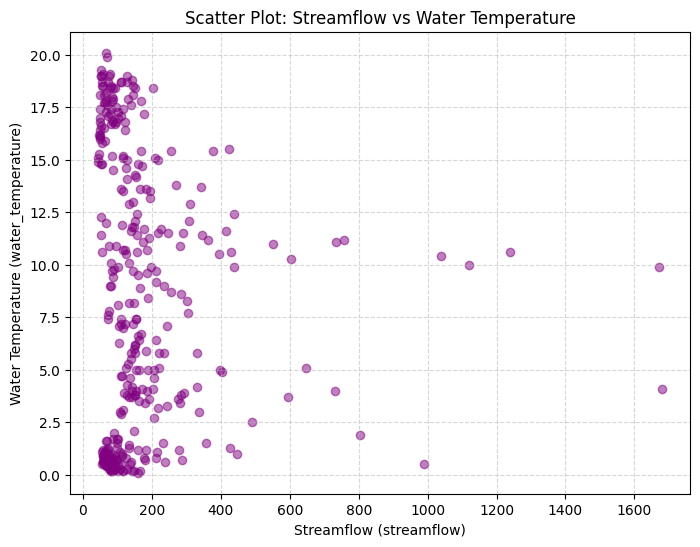

In [4]:
# Create a dual-axis plot comparing Streamflow and Water Temperature over time if a date/time column is present,
# or a scatter plot to show their correlation.

fig, ax1 = plt.subplots(figsize=(12, 6))

# Assuming there is a datetime or index to plot against. If there's a specific 'date' or 'datetime' column,
# we can convert it, otherwise we use the index.
time_col = None
for col in df.columns:
    if 'date' in col.lower() or 'time' in col.lower():
        time_col = col
        df[time_col] = pd.to_datetime(df[time_col])
        df = df.sort_values(by=time_col)
        break

x_axis = df[time_col] if time_col else df.index
x_label = time_col if time_col else 'Index'

# Find the correct column names for streamflow and water temperature
flow_col = [col for col in df.columns if 'streamflow' in col.lower() or 'flow' in col.lower()][0]
temp_col = [col for col in df.columns if 'temperature' in col.lower() or 'temp' in col.lower()][0]

# Plotting Streamflow
color = 'tab:blue'
ax1.set_xlabel(x_label)
ax1.set_ylabel(f'Streamflow ({flow_col})', color=color)
ax1.plot(x_axis, df[flow_col], color=color, alpha=0.7, label='Streamflow')
ax1.tick_params(axis='y', labelcolor=color)

# Instantiating a second axes that shares the same x-axis
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel(f'Water Temperature ({temp_col})', color=color)
ax2.plot(x_axis, df[temp_col], color=color, alpha=0.7, label='Water Temp')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Comparison of Streamflow and Water Temperature')
fig.tight_layout()
plt.show()

# Also create a scatter plot to show direct correlation
plt.figure(figsize=(8, 6))
plt.scatter(df[flow_col], df[temp_col], alpha=0.5, color='purple')
plt.xlabel(f'Streamflow ({flow_col})')
plt.ylabel(f'Water Temperature ({temp_col})')
plt.title('Scatter Plot: Streamflow vs Water Temperature')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()